# Square-root error and random walks

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part I, chapters "What is a 'good approximation'?" and "Square root error and random walks".*

> If you are trying to estimate a number, say, around ten thousand, and you get it right to within a hundred, let us celebrate this kind of accuracy by saying that you have made an approximation with *square-root error* ($\sqrt{10{,}000}=100$).

The Riemann Hypothesis, in its first formulation in the book, says that $\operatorname{Li}(X)$ approximates $\pi(X)$ with essentially square-root error. Why is square-root error the "gold standard"? Because it is exactly the error that pure chance produces. In this notebook you will:

1. take a random walk and watch it stay within a few multiples of $\sqrt{X}$ of home;
2. average many walks and find the law $\sqrt{2/\pi}\,\sqrt{X}$ that the book's figures show;
3. see where the constant $\sqrt{2/\pi}$ comes from;
4. act out the book's fable of the devil's committee, whose counting errors behave just like a random walk.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def walks(count, steps, seed=0):
    "count random walks of the given number of steps: row i is walk i's position after each step."
    rng = np.random.default_rng(seed)
    return np.cumsum(rng.choice([-1, 1], size=(count, steps)), axis=1)

## 1. One random walk

> To take a random walk along a (straight) east–west path you would start at your home base, but every minute, say, take a step along the path, each step being of the same length, but randomly either east or west. After $X$ minutes, how far are you from your home base?

Below, the walk's position after $n$ steps (east is up), and the curves $\pm\sqrt{n}$ and $\pm 2\sqrt{n}$. Change the seed to take a different walk: almost every walk stays inside the outer curves almost all the time, even though nothing forces it to.

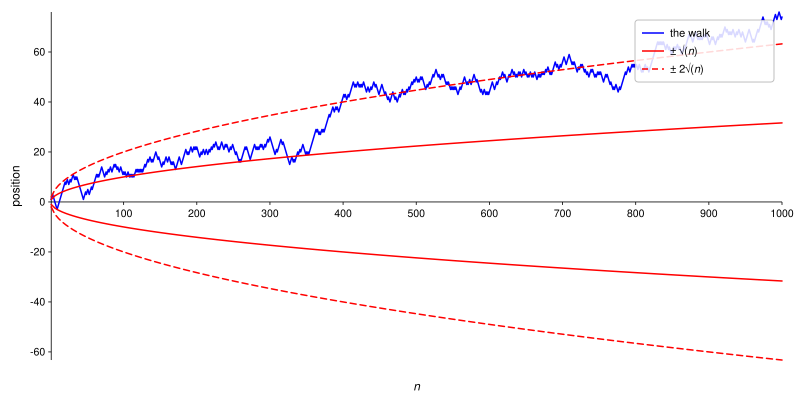

final position: 74   (sqrt(1000) = 31.6)


In [2]:
@interact
def one_walk(steps=selector([100, 1000, 10^4, 10^5], default=1000, label='steps'),
             seed=slider(0, 50, 1, 0, label='seed')):
    w = walks(1, steps, seed)[0]
    stride = max(1, steps // 3000)
    n = np.arange(1, steps + 1)
    g = list_plot(list(zip(n[::stride], w[::stride])), plotjoined=True, color='blue', legend_label='the walk')
    for c, style in [(1, '-'), (2, '--')]:
        g += plot(lambda t: c * sqrt(t), (1, steps), color='red', linestyle=style, legend_label=r'$\pm %s\sqrt{n}$' % ('' if c == 1 else c))
        g += plot(lambda t: -c * sqrt(t), (1, steps), color='red', linestyle=style)
    show(g, axes_labels=['$n$', 'position'], figsize=[8, 4])
    print('final position: %d   (sqrt(%d) = %.1f)' % (w[-1], steps, sqrt(steps.n())))

## 2. Many random walks, and their average distance from home

How far from home does a walker end up after $X$ steps? For one walk it could be anything from $0$ to $X$. But the **average** distance, over many walkers, follows a precise law. The book shows this with figures of $3$, $10$, $100$ and $1000$ walks:

> The red curve in each figure below is the graph of the quantity $\sqrt{\frac{2}{\pi}}\cdot\sqrt{X}$ over the $X$-axis. As the number of random walks increases, the red curve better and better approximates the average distance.

Here are those figures, live. The left plot shows (at most 30 of) the walks; the right plot shows the average of $|\text{position}|$ over all of them, against $\sqrt{2/\pi}\,\sqrt{X}$.

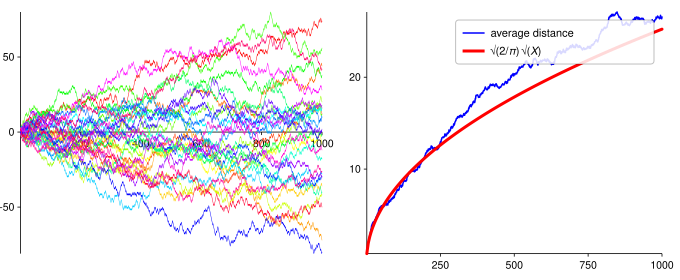

In [3]:
@interact
def many_walks(count=selector([3, 10, 100, 1000], default=100, label='number of walks'),
               steps=selector([100, 1000, 10^4], default=1000, label='steps'),
               seed=slider(0, 50, 1, 0, label='seed')):
    W = walks(count, steps, seed)
    n = np.arange(1, steps + 1)
    stride = max(1, steps // 1000)
    left = sum(list_plot(list(zip(n[::stride], w[::stride])), plotjoined=True, thickness=0.3,
                         color=hue(i / min(count, 30))) for i, w in enumerate(W[:30]))
    mean = np.abs(W).mean(axis=0)
    right = list_plot(list(zip(n[::stride], mean[::stride])), plotjoined=True, color='blue', legend_label='average distance')
    right += plot(lambda t: sqrt(2 / pi) * sqrt(t), (1, steps), color='red', thickness=2, legend_label=r'$\sqrt{2/\pi}\,\sqrt{X}$')
    show(graphics_array([left, right]), figsize=[10, 4])

## 3. Where does $\sqrt{2/\pi}$ come from?

After $X$ steps a walk's position is a sum of $X$ independent steps of $\pm 1$. Each step has mean $0$ and variance $1$, so the position has mean $0$ and variance $X$, and by the Central Limit Theorem it is approximately normally distributed with standard deviation $\sqrt{X}$. For a standard normal random variable $Z$,
$$\mathbb{E}\,|Z| \;=\; 2\int_0^\infty z\,\frac{e^{-z^2/2}}{\sqrt{2\pi}}\,dz \;=\; \sqrt{\frac{2}{\pi}} \approx 0.798,$$
so the average distance after $X$ steps is about $\sqrt{2/\pi}\,\sqrt{X}$.

Check both claims below: the histogram of final positions of many walks against the normal density with standard deviation $\sqrt{X}$, and the integral itself.

E|Z| = sqrt(2)/sqrt(pi) = 0.797884560802865
[interactive controls: run the cell to use them]


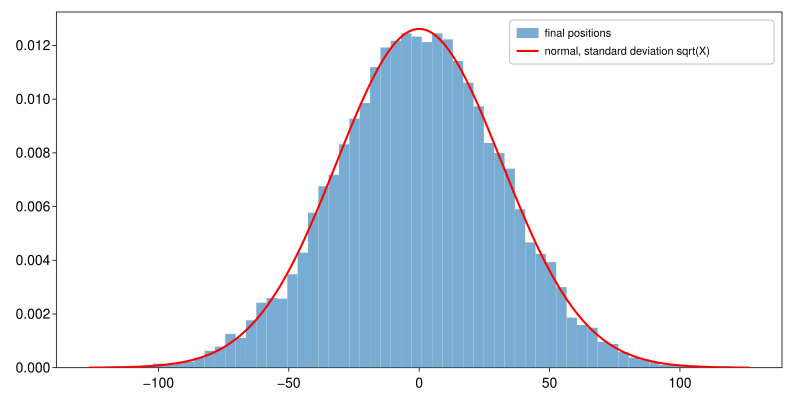

average |final position|: 25.47    sqrt(2/pi) sqrt(X): 25.23


In [4]:
z = var('z')
print('E|Z| =', 2 * integral(z * exp(-z^2 / 2) / sqrt(2 * pi), z, 0, oo), '=', N(sqrt(2 / pi)))

@interact
def final_positions(steps=selector([100, 1000, 10^4], default=1000, label='steps'),
                    count=selector([1000, 10^4], default=10^4, label='number of walks')):
    finals = walks(count, steps, seed=1)[:, -1]
    plt.figure(figsize=(8, 4))
    plt.hist(finals, bins=60, density=True, color='tab:blue', alpha=0.6, label='final positions')
    t = np.linspace(-4 * np.sqrt(steps), 4 * np.sqrt(steps), 400)
    plt.plot(t, np.exp(-t**2 / (2 * steps)) / np.sqrt(2 * np.pi * steps), 'r', label='normal, standard deviation sqrt(X)')
    plt.legend()
    plt.show()
    print('average |final position|: %.2f    sqrt(2/pi) sqrt(X): %.2f' % (np.abs(finals).mean(), np.sqrt(2 / np.pi * steps)))

## 4. The devil's committee

The book makes the connection with prime counting through a fable:

> Imagine that the devil had the idea of saddling a large committee of people with the task of finding values of $\pi(X)$ for various large numbers $X$. … He gives each committee member a copy of the list of all prime numbers between $1$ and one of the large numbers $X$ in which he was interested. … But since they are human, they will indeed be making mistakes, say $1\%$ of the time. Assume further that it is just as likely for them to make the mistake of undercounting or overcounting.

Each member's running error is a random walk that only moves at the $1\%$ of items where a mistake happens. After counting the $\pi(X)$ primes up to $X$, a member's error has standard deviation $\sqrt{0.01\,\pi(X)} = 0.1\sqrt{\pi(X)}$: square-root error again. Below, a committee counts the primes up to $X$; the histogram shows their errors, and the red lines mark $\pm 0.1\sqrt{\pi(X)}$ (one standard deviation).

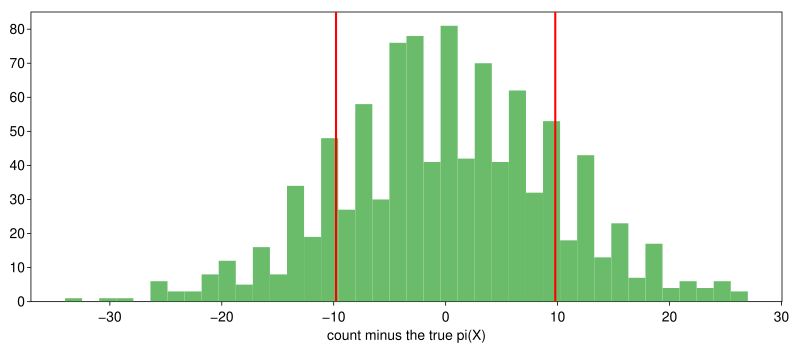

pi(100000) = 9592; the committee errors have standard deviation 9.8; sqrt(rate * pi(X)) = 9.8


In [5]:
@interact
def committee(X=selector([10^4, 10^5, 10^6], default=10^5, label='X'),
              members=selector([100, 1000], default=1000, label='committee members'),
              rate=selector([0.01, 0.05], default=0.01, label='mistake rate')):
    count = prime_pi(X)
    rng = np.random.default_rng(2)
    # each member makes a mistake on each item with probability `rate`, as likely +1 as -1; for a small rate the
    # number of mistakes is (very nearly) Poisson with mean rate * count, and each mistake is a step of +1 or -1
    mistakes = rng.poisson(rate * count, size=members)
    errors = np.array([rng.choice([-1, 1], size=int(m)).sum() for m in mistakes])
    sd = sqrt(rate * count).n()
    plt.figure(figsize=(8, 3.5))
    plt.hist(errors, bins=40, color='tab:green', alpha=0.7)
    for s in (-sd, sd):
        plt.axvline(s, color='r')
    plt.xlabel('count minus the true pi(X)')
    plt.show()
    print('pi(%d) = %d; the committee errors have standard deviation %.1f; sqrt(rate * pi(X)) = %.1f'
          % (X, count, errors.std(), sd))

## 5. The primes take a walk

The book's first formulation of the Riemann Hypothesis:

**The Riemann Hypothesis (first formulation):**

> For any real number $X$ the number of prime numbers less than $X$ is approximately $\operatorname{Li}(X)$ and this approximation is essentially square root accurate.

And it pictures the error $|\operatorname{Li}(X) - \pi(X)|$ as a walk:

> … the result of a walk having roughly $X$ steps where you move by the following rule: go east by a distance of $1/\log N$ feet if $N$ is not a prime and west by a distance of $1-\frac{1}{\log N}$ feet if $N$ is a prime. Your distance, then, from home base after $X$ steps is approximately $|\operatorname{Li}(X)-\pi(X)|$ feet.

Each step has average $0$ if "$N$ is prime" happens with probability $1/\log N$, which is Gauss's guess. Below, the blue walk uses the actual primes; the orange one replaces them with **random "primes"**, each $N$ chosen with probability $1/\log N$ (Cramér's model). The random walk wanders on the scale $\sqrt{X/\log X}$; the primes' walk stays much closer to home, drifting slowly east. That drift is the $\tfrac12\operatorname{li}(\sqrt{X})$ term, explained in *How good is $\operatorname{Li}(x)$?* The Riemann Hypothesis says the primes' walk never strays further than square-root distance.

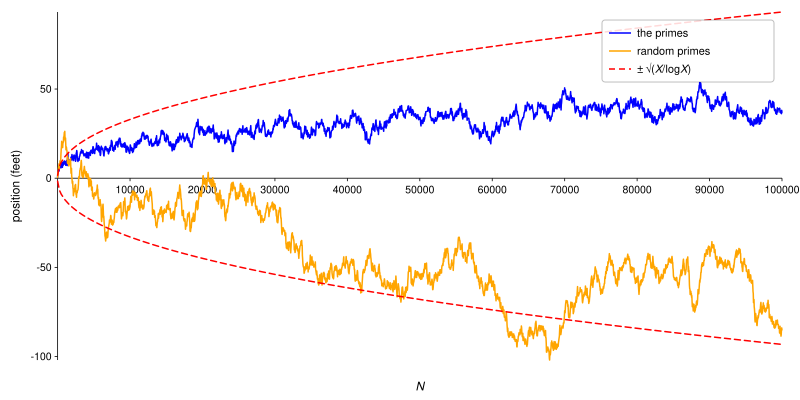

position of the primes' walk at X = 100000: 37.61    Li(X) - pi(X) = 36.76


In [6]:
from scipy.special import expi
def Li_value(x):
    "Li(x) = integral from 2 to x of dt/log t."
    return expi(float(log(x))) - expi(float(log(2)))

@interact
def prime_walk(X=selector([10^3, 10^4, 10^5, 10^6], default=10^5, label='X'),
               seed=slider(0, 50, 1, 0, label='seed for the random primes')):
    N = np.arange(2, X + 1, dtype=float)
    p = 1 / np.log(N)
    is_prime = np.zeros(X + 1, dtype=bool)
    is_prime[np.array(prime_range(X + 1))] = True
    actual = np.cumsum(np.where(is_prime[2:], -(1 - p), p))
    rng = np.random.default_rng(seed)
    model = np.cumsum(np.where(rng.random(len(N)) < p, -(1 - p), p))
    stride = max(1, len(N) // 3000)
    g = list_plot(list(zip(N[::stride], actual[::stride])), plotjoined=True, color='blue', legend_label='the primes')
    g += list_plot(list(zip(N[::stride], model[::stride])), plotjoined=True, color='orange', legend_label='random primes')
    for c in (1, -1):
        g += plot(lambda t: c * sqrt(t / log(t)), (2, X), color='red', linestyle='--',
                  legend_label=r'$\pm\sqrt{X/\log X}$' if c == 1 else None)
    show(g, axes_labels=['$N$', 'position (feet)'], figsize=[8, 4])
    print('position of the primes\' walk at X = %d: %.2f    Li(X) - pi(X) = %.2f' % (X, actual[-1], Li_value(X) - prime_pi(X)))

## Things to try

1. In section 2, how many walks do you need before the average distance is within $1\%$ of $\sqrt{2/\pi}\,\sqrt{X}$ at $X = 1000$?
2. Change the steps to $\pm 1$ with probabilities $0.6$ and $0.4$. What happens to the average distance? (Hint: the walk now drifts, and the error is no longer square-root size.)
3. In section 4, the mistakes are "as likely over as under". Make overcounting twice as likely as undercounting. How does the committee's error grow with $X$ now?
4. A walk returns home infinitely often (with probability $1$). Estimate, from simulations, how many times a walk of $10^4$ steps visits $0$. Compare with $\sqrt{2X/\pi}$.

---
*Adapted and greatly expanded from the code that drew the figures in* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*